Implementation of Max-Cut problem as QAOA for a simple example of graph with 3 nodes.
I have math and notes for this example in the notebook.


### Weighted Max-Cut Problem

Consider the weighted graph $G=(V,E,w)$, where

$$
V=\{0,1,2\}
$$

$$
E=\{(0,1),(1,2),(0,2)\}
$$

with edge weights

$$
w_{01}=1,\qquad w_{12}=2,\qquad w_{02}=3.
$$

The Max-Cut objective is

$$
\max_{x\in\{0,1\}^3}
C(x)=\sum_{(i,j)\in E}w_{ij}(x_i+x_j-2x_ix_j).
$$

The corresponding Ising Hamiltonian is

$$
H_C=Z_0Z_1+2Z_1Z_2+3Z_0Z_2.
$$


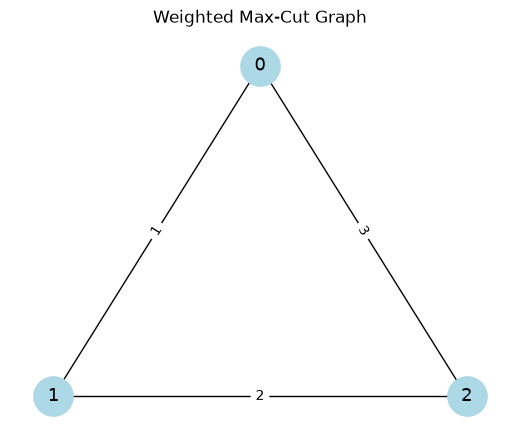

In [34]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_weighted_edges_from([
    (0, 1, 1),
    (1, 2, 2),
    (0, 2, 3)
])

pos = {
    0: (0, 1),
    1: (-1, 0),
    2: (1, 0)
}

plt.figure(figsize=(5, 4))

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=800,
    font_size=13
)

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=nx.get_edge_attributes(G, "weight")
)

plt.title("Weighted Max-Cut Graph")
plt.axis("off")
plt.show()


THE CODE FOR QAOA

In [35]:
import numpy as np
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

In [36]:
# Define Graph
n = 3
edges = [
    (0, 1, 1),
    (1, 2, 2),
    (0, 2, 3)
]

num_of_repetitions = 3

In [37]:
# Cost Hamiltonian
# H_C = Z0 Z1 + 2 Z1 Z2 + 3 Z0 Z2

H_C = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, j], w) for i, j, w in edges],
    num_qubits=n
)

In [38]:
# QAOA Circuit

def create_circuit(gamma, beta):
    qc = QuantumCircuit(n)

    # Initial state |+>^3
    for i in range(n):
        qc.h(i)

    # Cost Hamiltonian evolution
    for i, j, w in edges:
        qc.rzz(2 * gamma * w, i, j)

    # Mixer Hamiltonian evolution
    for i in range(n):
        qc.rx(2 * beta, i)

    return qc

In [39]:
# Expectation value of cost Hamiltonian
def energy(params):
    gamma, beta = params

    qc = create_circuit(gamma, beta)
    state = Statevector.from_instruction(qc)

    return float(np.real(state.expectation_value(H_C)))



In [40]:
# Optimization cell — run after defining create_circuit and energy
result = minimize(
    energy,
    x0=[0.3, 0.4],
    method="COBYLA",
    options={"maxiter": 2000, "tol": 1e-9}
)

gamma_opt, beta_opt = result.x


print("Optimal gammas:", gamma_opt)
print("Optimal betas:", beta_opt)
print("Minimum energy:", result.fun)

Optimal gammas: 2.2731664785908228
Optimal betas: 0.5970128438031426
Minimum energy: -2.858527262754192


In [42]:
# Inspect the optimized circuit
qc = create_circuit(gamma_opt, beta_opt)
state = Statevector.from_instruction(qc)

print(qc.draw("text"))
print("Probabilities:", state.probabilities_dict())


     ┌───┐                                       ┌───────────┐
q_0: ┤ H ├─■─────────────────────────■───────────┤ Rx(1.194) ├
     ├───┤ │ZZ(4.5463)               │           ├───────────┤
q_1: ┤ H ├─■────────────■────────────┼───────────┤ Rx(1.194) ├
     ├───┤              │ZZ(9.0927)  │ZZ(13.639) ├───────────┤
q_2: ┤ H ├──────────────■────────────■───────────┤ Rx(1.194) ├
     └───┘                                       └───────────┘
Probabilities: {np.str_('000'): np.float64(0.009917542172591345), np.str_('001'): np.float64(0.061522659921210976), np.str_('010'): np.float64(0.08712890676364204), np.str_('011'): np.float64(0.3414308911425556), np.str_('100'): np.float64(0.3414308911425556), np.str_('101'): np.float64(0.08712890676364204), np.str_('110'): np.float64(0.061522659921210976), np.str_('111'): np.float64(0.009917542172591345)}
